# Desafio: Investigue uma Pergunta com Python
## Análise Exploratória e Teste de Hipótese — Acidentes nas Rodovias Federais do Maranhão (PRF 2025)

---

### 1. A Base Escolhida
* **Fonte:** Dados Abertos da Polícia Rodoviária Federal (PRF) — *Acidentes 2025 (Agrupados por ocorrência)* (`datatran2025_original.csv`).
* **Recorte Analítico:** Filtramos os registros referentes ao estado do **Maranhão (`uf == 'MA'`)**, totalizando **1.262 ocorrências** e **30 variáveis** (superando amplamente o requisito mínimo de 300 linhas).
* **Justificativa:** O Maranhão possui corredores rodoviários estratégicos para o escoamento agroindustrial e transporte de passageiros no Norte/Nordeste (como as BRs 135, 316, 010, 222 e 230). Compreender onde, quando e por que os sinistros graves ocorrem permite orientar políticas de engenharia viária e alocação eficiente de equipes de fiscalização da PRF.

### 2. As Perguntas Investigadas e sua Relevância de Negócio

1. **Distribuição Espacial:** *Quais rodovias federais (BRs) e municípios concentram a maior parte dos acidentes e das mortes no Maranhão em 2025?*
   * **Relevância para decisão:** Identifica os trechos prioritários para instalação de radares, postos móveis da PRF e obras de infraestrutura.
2. **Padrão Temporal:** *Em quais dias da semana, faixas horárias e meses do ano ocorre o maior volume de sinistros nas rodovias maranhenses?*
   * **Relevância para decisão:** Orienta o escalonamento operacional de viaturas e campanhas preventivas nos períodos de maior risco.
3. **Causas e Tipologia:** *Quais são as principais causas e tipos de acidentes no Maranhão, e quais ocorrências apresentam a maior severidade (letalidade)?*
   * **Relevância para decisão:** Direciona o foco das abordagens educativas e de fiscalização (ex.: ultrapassagens proibidas e contramão vs. falta de atenção).
4. **Comparação entre Dois Grupos (Teste de Hipótese):** *Acidentes ocorridos em **pistas simples** apresentam média de **vítimas graves ou fatais** (`mortos + feridos_graves`) estatisticamente maior do que acidentes em **pistas duplas**?*
   * **Relevância para decisão:** Fornece evidência estatística robusta para justificar investimentos públicos na duplicação de trechos rodoviários críticos.

---
### 3. Preparação dos Dados (Etapa 01 — Carregar e Limpar)

Nesta etapa, carregamos o arquivo original via **caminho relativo** (`dados/datatran2025_original.csv`), inspecionamos dimensões, tipos de colunas, valores ausentes e duplicados, e realizamos as transformações necessárias sem alterar o arquivo original.

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

# Leitura da base original via caminho relativo corrigido
df_bruto = pd.read_csv('dados/datatran2025_original.csv', sep=';', encoding='latin1')
print(f"Base nacional completa: {df_bruto.shape[0]} linhas x {df_bruto.shape[1]} colunas")

# Filtragem para o estado do Maranhão (MA)
df_ma = df_bruto[df_bruto['uf'] == 'MA'].copy()
print(f"Recorte Maranhão (MA): {df_ma.shape[0]} linhas x {df_ma.shape[1]} colunas")
print(df_ma[['id', 'data_inversa', 'dia_semana', 'horario', 'br', 'municipio', 'tipo_pista', 'mortos', 'feridos_graves']].head(3))

Base nacional completa: 72529 linhas x 30 colunas
Recorte Maranhão (MA): 1262 linhas x 30 colunas
         id data_inversa    dia_semana   horario   br           municipio  \
27   652793   02/01/2025  quinta-feira  06:50:00  135    MIRANDA DO NORTE   
296  654015   09/01/2025  quinta-feira  07:00:00  230  SAO JOAO DOS PATOS   
318  654077   09/01/2025  quinta-feira  17:40:00  135            SAO LUIS   

    tipo_pista  mortos  feridos_graves  
27     Simples       0               0  
296    Simples       1               1  
318      Dupla       0               0  


In [34]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [35]:
# Inspeção de tipos de dados, valores ausentes e registros duplicados
print("=== Tipos das colunas ===")
print(df_ma.dtypes)

print("\n=== Valores ausentes no recorte MA ===")
print(f"Total de células ausentes no MA: {df_ma.isna().sum().sum()}")

print(f"\n=== Registros duplicados no recorte MA: {df_ma.duplicated().sum()} ===")

=== Tipos das colunas ===
id                         int64
data_inversa              object
dia_semana                object
horario                   object
uf                        object
br                         int64
km                        object
municipio                 object
causa_acidente            object
tipo_acidente             object
classificacao_acidente    object
fase_dia                  object
sentido_via               object
condicao_metereologica    object
tipo_pista                object
tracado_via               object
uso_solo                  object
pessoas                    int64
mortos                     int64
feridos_leves              int64
feridos_graves             int64
ilesos                     int64
ignorados                  int64
feridos                    int64
veiculos                   int64
latitude                  object
longitude                 object
regional                  object
delegacia                 object
uop              

In [36]:
# Tratamento e engenharia de atributos (sem modificar o arquivo original)
# 1. Converter colunas numéricas que usam vírgula como separador decimal
for col in ['km', 'latitude', 'longitude']:
    df_ma[col] = df_ma[col].astype(str).str.replace(',', '.', regex=False).astype(float)

# 2. Converter datas e extrair mês e hora cheia
df_ma['data_dt'] = pd.to_datetime(df_ma['data_inversa'], format='%d/%m/%Y')
df_ma['mes'] = df_ma['data_dt'].dt.month
df_ma['hora'] = pd.to_datetime(df_ma['horario'], format='%H:%M:%S').dt.hour

# 3. Ordenar cronologicamente os dias da semana
ordem_dias = ['segunda-feira', 'terça-feira', 'quarta-feira', 'quinta-feira', 'sexta-feira', 'sábado', 'domingo']
df_ma['dia_semana'] = pd.Categorical(df_ma['dia_semana'], categories=ordem_dias, ordered=True)

# 4. Criar indicadores de gravidade por ocorrência
df_ma['total_vitimas'] = df_ma['mortos'] + df_ma['feridos']
df_ma['vitimas_graves_fatais'] = df_ma['mortos'] + df_ma['feridos_graves']

print("Período analisado:", df_ma['data_dt'].min().strftime('%d/%m/%Y'), "a", df_ma['data_dt'].max().strftime('%d/%m/%Y'))
print("Tipos convertidos e variáveis derivadas criadas com sucesso!")

Período analisado: 01/01/2025 a 31/12/2025
Tipos convertidos e variáveis derivadas criadas com sucesso!


---
### 4. Análise Exploratória por Pergunta (Etapa 02 — Explorar)

Utilizamos filtros e agrupamentos com Pandas (`groupby`, `agg`, `value_counts`) para responder às três primeiras perguntas investigativas.

In [37]:
# Pergunta 1: Rodovias (BRs) e Municípios com mais acidentes e mortes
resumo_br = df_ma.groupby('br').agg(
    acidentes=('id', 'count'),
    mortos=('mortos', 'sum'),
    feridos_graves=('feridos_graves', 'sum'),
    vitimas_totais=('total_vitimas', 'sum')
).sort_values(by='acidentes', ascending=False)
resumo_br['pct_acidentes'] = (resumo_br['acidentes'] / len(df_ma) * 100).round(2)
resumo_br['mortos_por_100_acid'] = (resumo_br['mortos'] / resumo_br['acidentes'] * 100).round(2)

print("=== Resumo por Rodovia Federal (BR) no Maranhão ===")
print(resumo_br)

resumo_mun = df_ma.groupby('municipio').agg(
    acidentes=('id', 'count'),
    mortos=('mortos', 'sum'),
    feridos_graves=('feridos_graves', 'sum')
).sort_values(by='acidentes', ascending=False).head(10)
resumo_mun['pct_acidentes'] = (resumo_mun['acidentes'] / len(df_ma) * 100).round(2)

print("\n=== Top 10 Municípios em Ocorrências no Maranhão ===")
print(resumo_mun)

=== Resumo por Rodovia Federal (BR) no Maranhão ===
     acidentes  mortos  feridos_graves  vitimas_totais  pct_acidentes  \
br                                                                      
135        390      49             110             445          30.90   
316        244      72             109             327          19.33   
10         221      46              78             269          17.51   
222        152      46              60             195          12.04   
230        119      24              55             142           9.43   
226        104      24              40             148           8.24   
402         26      11              12              34           2.06   
330          5       9               3              15           0.40   
0            1       0               1               1           0.08   

     mortos_por_100_acid  
br                        
135                12.56  
316                29.51  
10                 20.81  
222      

In [38]:
# Pergunta 2: Padrão Temporal (Dia da Semana, Mês e Hora)
resumo_dia = df_ma.groupby('dia_semana', observed=False).agg(
    acidentes=('id', 'count'),
    mortos=('mortos', 'sum'),
    media_vitimas_graves_fatais=('vitimas_graves_fatais', 'mean')
)
resumo_dia['pct_acidentes'] = (resumo_dia['acidentes'] / len(df_ma) * 100).round(2)
print("=== Acidentes por Dia da Semana ===")
print(resumo_dia.round(3))

resumo_mes = df_ma.groupby('mes').agg(
    acidentes=('id', 'count'),
    mortos=('mortos', 'sum')
)
print("\n=== Acidentes por Mês ===")
print(resumo_mes)

print("\n=== Top 5 Horários (Hora cheia) com mais sinistros ===")
print(df_ma['hora'].value_counts().head(5))

=== Acidentes por Dia da Semana ===
               acidentes  mortos  media_vitimas_graves_fatais  pct_acidentes
dia_semana                                                                  
segunda-feira        175      39                        0.594          13.87
terça-feira          166      35                        0.530          13.15
quarta-feira         142      21                        0.542          11.25
quinta-feira         151      32                        0.530          11.97
sexta-feira          189      39                        0.593          14.98
sábado               213      58                        0.610          16.88
domingo              226      57                        0.699          17.91

=== Acidentes por Mês ===
     acidentes  mortos
mes                   
1           65      13
2           90      16
3           95      17
4           86      13
5          109      30
6           88      18
7          115      27
8           90      27
9          116

In [39]:
# Pergunta 3: Principais Causas e Tipos de Acidente
resumo_causa = df_ma.groupby('causa_acidente').agg(
    acidentes=('id', 'count'),
    mortos=('mortos', 'sum'),
    vitimas_graves_fatais=('vitimas_graves_fatais', 'sum')
).sort_values(by='acidentes', ascending=False).head(8)
resumo_causa['pct_acidentes'] = (resumo_causa['acidentes'] / len(df_ma) * 100).round(2)
print("=== Top 8 Causas de Acidentes no Maranhão ===")
print(resumo_causa)

resumo_tipo = df_ma.groupby('tipo_acidente').agg(
    acidentes=('id', 'count'),
    mortos=('mortos', 'sum'),
    vitimas_graves_fatais=('vitimas_graves_fatais', 'sum')
).sort_values(by='acidentes', ascending=False).head(8)
resumo_tipo['mortos_por_100_acid'] = (resumo_tipo['mortos'] / resumo_tipo['acidentes'] * 100).round(2)
print("\n=== Top 8 Tipos de Acidente e Letalidade ===")
print(resumo_tipo)

=== Top 8 Causas de Acidentes no Maranhão ===
                                                    acidentes  mortos  \
causa_acidente                                                          
Acessar a via sem observar a presença dos outro...        186      30   
Reação tardia ou ineficiente do condutor                  176      28   
Ausência de reação do condutor                            152      41   
Transitar na contramão                                    108      80   
Manobra de mudança de faixa                                68      14   
Ingestão de álcool pelo condutor                           67      10   
Ultrapassagem Indevida                                     58      19   
Condutor deixou de manter distância do veículo ...         54       2   

                                                    vitimas_graves_fatais  \
causa_acidente                                                              
Acessar a via sem observar a presença dos outro...                   

---
### 5. Estatística Descritiva e Visualizações (Etapa 03 — Descrever)

Calculamos medidas de tendência central (média e mediana), dispersão (desvio padrão, amplitude e intervalo interquartil) e tabelas de frequência, seguidas de gráficos que evidenciam os padrões encontrados.

In [40]:
# Estatística descritiva das variáveis numéricas principais
cols_est = ['pessoas', 'mortos', 'feridos_leves', 'feridos_graves', 'total_vitimas', 'vitimas_graves_fatais', 'veiculos']
estatisticas = pd.DataFrame({
    'Média': df_ma[cols_est].mean(),
    'Mediana': df_ma[cols_est].median(),
    'Desvio Padrão': df_ma[cols_est].std(),
    'Mínimo': df_ma[cols_est].min(),
    'Q1 (25%)': df_ma[cols_est].quantile(0.25),
    'Q3 (75%)': df_ma[cols_est].quantile(0.75),
    'IQR': df_ma[cols_est].quantile(0.75) - df_ma[cols_est].quantile(0.25),
    'Máximo': df_ma[cols_est].max()
}).round(3)

print("=== Medidas de Tendência Central e Dispersão (MA - 2025) ===")
print(estatisticas)

print("\n=== Tabela de Frequência: Classificação do Acidente ===")
freq_class = pd.DataFrame({
    'Frequência Absoluta': df_ma['classificacao_acidente'].value_counts(),
    'Frequência Relativa (%)': (df_ma['classificacao_acidente'].value_counts(normalize=True) * 100).round(2)
})
print(freq_class)

=== Medidas de Tendência Central e Dispersão (MA - 2025) ===
                       Média  Mediana  Desvio Padrão  Mínimo  Q1 (25%)  \
pessoas                2.704      2.0          1.775       1       2.0   
mortos                 0.223      0.0          0.507       0       0.0   
feridos_leves          0.655      0.0          0.911       0       0.0   
feridos_graves         0.371      0.0          0.652       0       0.0   
total_vitimas          1.249      1.0          1.033       0       1.0   
vitimas_graves_fatais  0.594      0.0          0.774       0       0.0   
veiculos               2.132      2.0          1.037       1       2.0   

                       Q3 (75%)  IQR  Máximo  
pessoas                     3.0  1.0      29  
mortos                      0.0  0.0       3  
feridos_leves               1.0  1.0       8  
feridos_graves              1.0  1.0       6  
total_vitimas               2.0  1.0      11  
vitimas_graves_fatais       1.0  1.0       6  
veiculos         

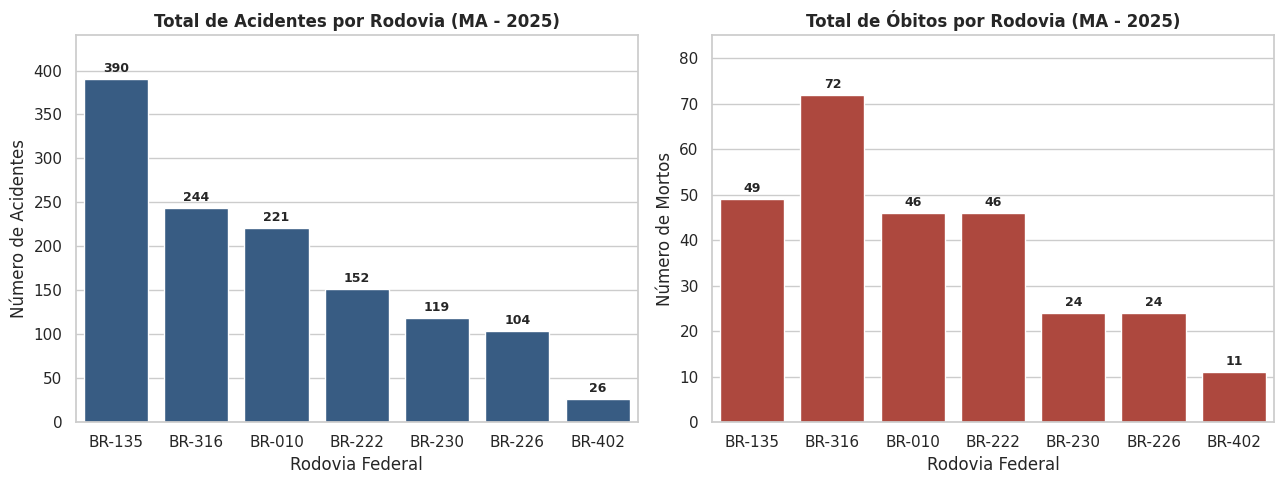

In [41]:
# Gráfico 1: Acidentes e Óbitos por Rodovia Federal (BR)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top_br = resumo_br.head(7).reset_index()
top_br['br_label'] = 'BR-' + top_br['br'].astype(str).str.zfill(3)

sns.barplot(data=top_br, x='br_label', y='acidentes', color='#2b5c8f', ax=axes[0])
axes[0].set_title('Total de Acidentes por Rodovia (MA - 2025)', fontweight='bold')
axes[0].set_xlabel('Rodovia Federal')
axes[0].set_ylabel('Número de Acidentes')
axes[0].set_ylim(0, 440)
for i, v in enumerate(top_br['acidentes']):
    axes[0].text(i, v + 8, str(int(v)), ha='center', fontsize=9, fontweight='bold')

sns.barplot(data=top_br, x='br_label', y='mortos', color='#c0392b', ax=axes[1])
axes[1].set_title('Total de Óbitos por Rodovia (MA - 2025)', fontweight='bold')
axes[1].set_xlabel('Rodovia Federal')
axes[1].set_ylabel('Número de Mortos')
axes[1].set_ylim(0, 85)
for i, v in enumerate(top_br['mortos']):
    axes[1].text(i, v + 1.5, str(int(v)), ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

/tmp/ipykernel_438/1377170004.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dias_curto, y=resumo_dia['acidentes'].values, palette='Blues_d', ax=axes[0])


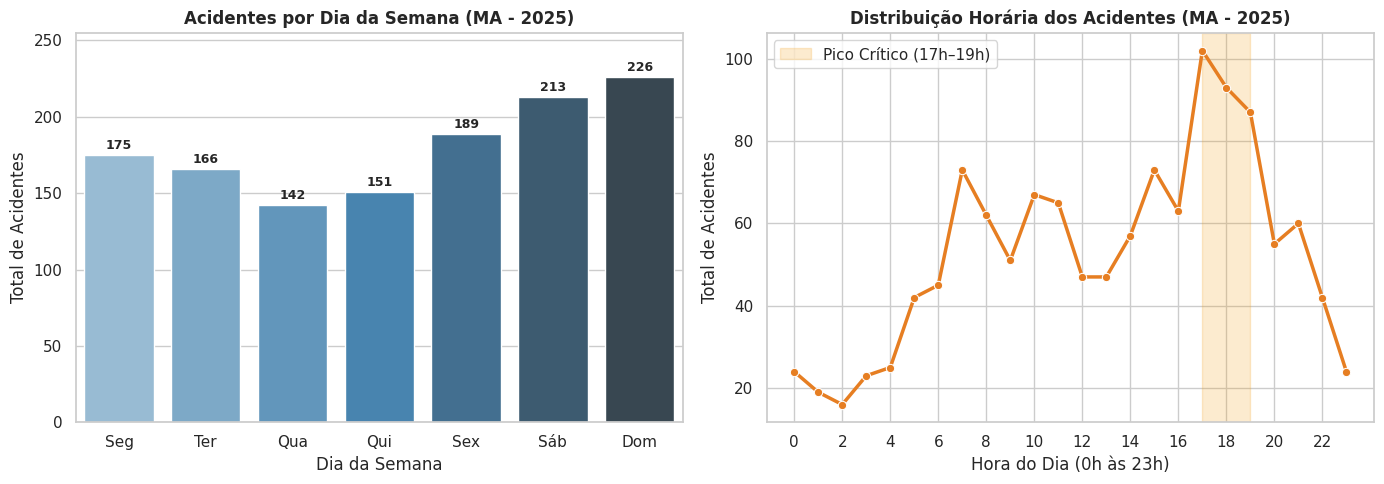

In [42]:
# Gráfico 2: Distribuição por Dia da Semana e Faixa Horária
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

dias_curto = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
sns.barplot(x=dias_curto, y=resumo_dia['acidentes'].values, palette='Blues_d', ax=axes[0])
axes[0].set_title('Acidentes por Dia da Semana (MA - 2025)', fontweight='bold')
axes[0].set_xlabel('Dia da Semana')
axes[0].set_ylabel('Total de Acidentes')
axes[0].set_ylim(0, 255)
for i, v in enumerate(resumo_dia['acidentes'].values):
    axes[0].text(i, v + 4, str(v), ha='center', fontsize=9, fontweight='bold')

horas_contagem = df_ma['hora'].value_counts().sort_index()
sns.lineplot(x=horas_contagem.index, y=horas_contagem.values, marker='o', color='#e67e22', linewidth=2.5, ax=axes[1])
axes[1].axvspan(17, 19, color='#f39c12', alpha=0.2, label='Pico Crítico (17h–19h)')
axes[1].set_title('Distribuição Horária dos Acidentes (MA - 2025)', fontweight='bold')
axes[1].set_xlabel('Hora do Dia (0h às 23h)')
axes[1].set_ylabel('Total de Acidentes')
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend()

plt.tight_layout()
plt.show()

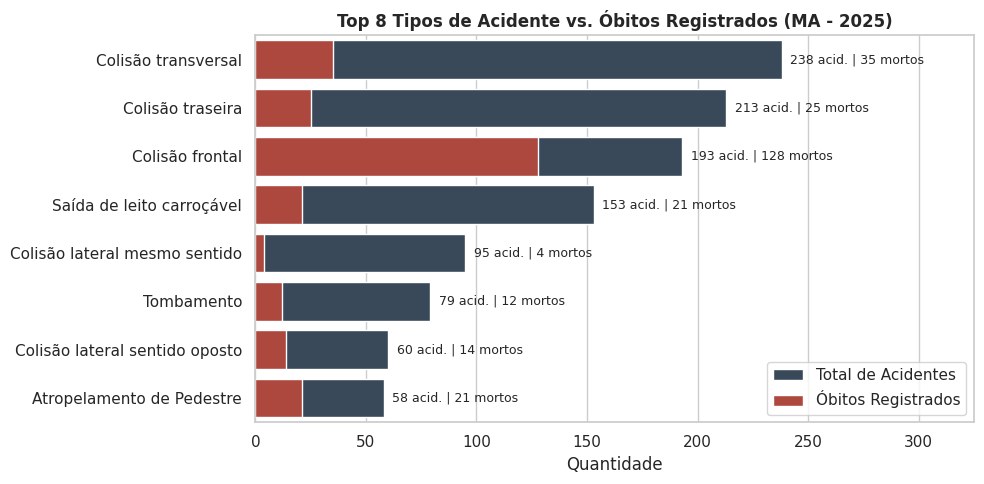

In [43]:
# Gráfico 3: Top 8 Tipos de Acidente vs. Óbitos
fig, ax = plt.subplots(figsize=(10, 5))
top_tipos = resumo_tipo.reset_index()
sns.barplot(data=top_tipos, y='tipo_acidente', x='acidentes', color='#34495e', ax=ax, label='Total de Acidentes')
sns.barplot(data=top_tipos, y='tipo_acidente', x='mortos', color='#c0392b', ax=ax, label='Óbitos Registrados')
ax.set_title('Top 8 Tipos de Acidente vs. Óbitos Registrados (MA - 2025)', fontweight='bold')
ax.set_xlabel('Quantidade')
ax.set_ylabel('')
ax.legend(loc='lower right')
for i, row in top_tipos.iterrows():
    ax.text(row['acidentes'] + 4, i, f"{int(row['acidentes'])} acid. | {int(row['mortos'])} mortos", va='center', fontsize=9)
ax.set_xlim(0, 325)
plt.tight_layout()
plt.show()

---
### 6. Teste de Hipótese (Etapa 04 — Testar)

**Pergunta de comparação entre dois grupos:** *Acidentes ocorridos em **pistas simples** geram um número médio de **vítimas graves ou fatais** (`mortos + feridos_graves`) estatisticamente superior ao de acidentes em **pistas duplas**?*

* **Hipótese Nula ($H_0$):** Não há diferença na distribuição/média de vítimas graves ou fatais entre acidentes em pista simples e pista dupla ($\mu_{\text{simples}} = \mu_{\text{dupla}}$).
* **Hipótese Alternativa ($H_1$):** Existe diferença estatisticamente significativa na gravidade dos acidentes entre pista simples e pista dupla ($\mu_{\text{simples}} \neq \mu_{\text{dupla}}$).
* **Nível de significância adotado ($\alpha$):** $0,05$ (5%).

In [44]:
# Separação dos dois grupos principais (Pista Simples vs. Pista Dupla)
pista_simples = df_ma[df_ma['tipo_pista'] == 'Simples']['vitimas_graves_fatais']
pista_dupla = df_ma[df_ma['tipo_pista'] == 'Dupla']['vitimas_graves_fatais']

print(f"Pista Simples -> n = {len(pista_simples)} | Média = {pista_simples.mean():.4f} | Mediana = {pista_simples.median():.1f} | DP = {pista_simples.std():.4f}")
print(f"Pista Dupla   -> n = {len(pista_dupla)} | Média = {pista_dupla.mean():.4f} | Mediana = {pista_dupla.median():.1f} | DP = {pista_dupla.std():.4f}")

# Verificação de normalidade (Shapiro-Wilk)
_, p_norm_s = stats.shapiro(pista_simples)
_, p_norm_d = stats.shapiro(pista_dupla)
print(f"\nTeste de Normalidade (Shapiro-Wilk): p_simples = {p_norm_s:.4e} | p_dupla = {p_norm_d:.4e}")

# Teste não-paramétrico de Mann-Whitney U (adequado para dados de contagem assimétricos)
u_stat, p_mw = stats.mannwhitneyu(pista_simples, pista_dupla, alternative='two-sided')

# Teste t de Welch (comparação paramétrica de médias com variâncias desiguais)
t_stat, p_welch = stats.ttest_ind(pista_simples, pista_dupla, equal_var=False)

print(f"\nResultado Mann-Whitney U: U = {u_stat:.2f} | valor-p = {p_mw:.4e}")
print(f"Resultado Teste t de Welch: t = {t_stat:.4f} | valor-p = {p_welch:.4e}")

if p_mw < 0.05:
    print("\nDECISÃO: Rejeitamos H0 (p < 0,05). A diferença é estatisticamente real e não ocorreu por acaso.")
else:
    print("\nDECISÃO: Não rejeitamos H0 (p >= 0,05).")

Pista Simples -> n = 926 | Média = 0.6890 | Mediana = 1.0 | DP = 0.8163
Pista Dupla   -> n = 303 | Média = 0.3234 | Mediana = 0.0 | DP = 0.5705

Teste de Normalidade (Shapiro-Wilk): p_simples = 3.7373e-35 | p_dupla = 5.3840e-26

Resultado Mann-Whitney U: U = 176590.50 | valor-p = 3.3693e-14
Resultado Teste t de Welch: t = 8.6307 | valor-p = 3.7560e-17

DECISÃO: Rejeitamos H0 (p < 0,05). A diferença é estatisticamente real e não ocorreu por acaso.


/tmp/ipykernel_438/984819869.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_pistas, x='tipo_pista', y='vitimas_graves_fatais', palette=['#e74c3c', '#2ecc71'], ax=axes[0])


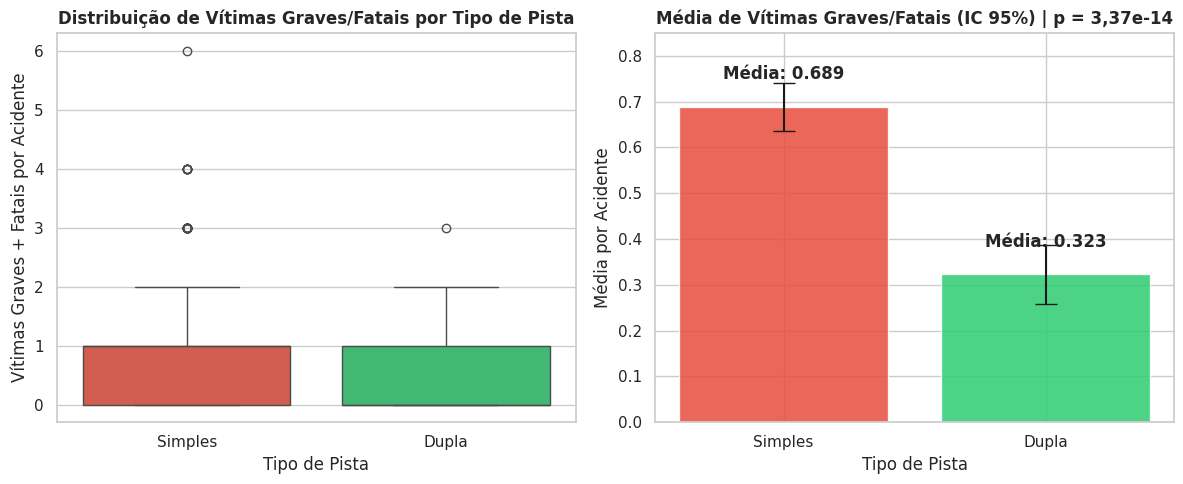

In [45]:
# Gráfico 4: Comparação Visual dos Grupos do Teste de Hipótese
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
df_pistas = df_ma[df_ma['tipo_pista'].isin(['Simples', 'Dupla'])].copy()

sns.boxplot(data=df_pistas, x='tipo_pista', y='vitimas_graves_fatais', palette=['#e74c3c', '#2ecc71'], ax=axes[0])
axes[0].set_title('Distribuição de Vítimas Graves/Fatais por Tipo de Pista', fontweight='bold')
axes[0].set_xlabel('Tipo de Pista')
axes[0].set_ylabel('Vítimas Graves + Fatais por Acidente')

medias = df_pistas.groupby('tipo_pista')['vitimas_graves_fatais'].agg(['mean', 'sem']).reset_index()
medias['ordem'] = medias['tipo_pista'].map({'Simples': 0, 'Dupla': 1})
medias = medias.sort_values('ordem').reset_index(drop=True)

axes[1].bar(medias['tipo_pista'], medias['mean'], yerr=1.96*medias['sem'], capsize=8, color=['#e74c3c', '#2ecc71'], alpha=0.85)
axes[1].set_title('Média de Vítimas Graves/Fatais (IC 95%) | p = 3,37e-14', fontweight='bold')
axes[1].set_xlabel('Tipo de Pista')
axes[1].set_ylabel('Média por Acidente')
for i, row in medias.iterrows():
    axes[1].text(i, row['mean'] + 0.06, f"Média: {row['mean']:.3f}", ha='center', fontweight='bold')
axes[1].set_ylim(0, 0.85)

plt.tight_layout()
plt.show()

---
### 7. Conclusões (Etapa 05 — Comunicar)

* **O que os dados mostraram:**
  1. **Concentração geográfica e letalidade distinta:** Em 2025, o Maranhão registrou **1.262 acidentes** e **281 mortos** nas rodovias federais. A **BR-135** lidera em volume total (**390 acidentes; 30,90%**), puxada pelo trecho urbano de **São Luís** (**237 acidentes**). Contudo, as rodovias **BR-316** (**72 mortos** em 244 acidentes) e **BR-222** (**46 mortos** em 152 acidentes) apresentam taxas de letalidade muito superiores.
  2. **Janelas críticas de risco:** Os fins de semana concentram **34,79%** das ocorrências (**domingo** com 226 e **sábado** com 213), e o intervalo entre **17h e 19h** responde sozinho por **22,35%** (282 acidentes) de todos os sinistros do dia. Sazonalmente, **dezembro** (150 acidentes) e **outubro** (141) são os meses mais críticos.
  3. **Impacto comprovado da duplicação viária:** O teste de hipótese comprovou ($p = 3,37 \times 10^{-14}$) que acidentes em **pista simples** geram, em média, **mais que o dobro** de vítimas graves ou fatais (**0,689** por ocorrência) em relação às **pistas duplas** (**0,323** por ocorrência).
* **Resultado inesperado:**
  * Embora as **colisões transversais** (238) e **traseiras** (213) sejam as mais frequentes, as **colisões frontais** (193 ocorrências) respondem por **128 óbitos — quase metade (45,55%) de todas as mortes** nas BRs do Maranhão em 2025 (uma letalidade alarmante de **66,3 mortes a cada 100 acidentes**), impulsionadas diretamente por ultrapassagens indevidas e tráfego na contramão em pistas simples.
* **Limitações da análise:**
  * A base registra apenas ocorrências atendidas pela PRF em rodovias federais, não contemplando rodovias estaduais (MAs) nem vias municipais sem atuação federal.
  * Não há dados de Volume Médio Diário (VMD) de tráfego por trecho na base, o que impede calcular a taxa de risco relativizada pelo fluxo total de veículos.

---
### 8. Reflexão

* **Por que Python foi mais eficiente do que planilhas:**
  1. **Volume e velocidade:** Filtrar 1.262 registros maranhenses dentro de uma base nacional de **72.529 linhas** e cruzar múltiplos agrupamentos (`groupby`) levou milissegundos, sem travamentos.
  2. **Rigor estatístico nativo:** Executar os testes de **Shapiro-Wilk**, **Mann-Whitney U** e **Teste t de Welch** com `scipy.stats` é direto, auditável e livre de fórmulas manuais propensas a erro.
  3. **Reprodutibilidade:** Qualquer membro da equipe ou avaliador pode clicar em *"Reiniciar e executar tudo"* e reproduzir integralmente limpeza, tabelas e gráficos sem alterar o arquivo original em `dados/`.
* **Divisão de trabalho da equipe:**
  * **Etapa 1 (Preparação e Limpeza):** Carregamento, validação de integridade, tipagem e criação das variáveis de gravidade.
  * **Etapa 2 (Exploração e Estatística):** Construção das tabelas agrupadas por BR, município, temporalidade e causas.
  * **Etapa 3 (Visualização e Teste de Hipótese):** Geração dos gráficos, formalização de $H_0$/$H_1$ e execução dos testes estatísticos.
  * **Etapa 4 (Documentação e Revisão):** Redação das conclusões, revisão do `README.md` e validação final no GitHub.